In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, ifftshift

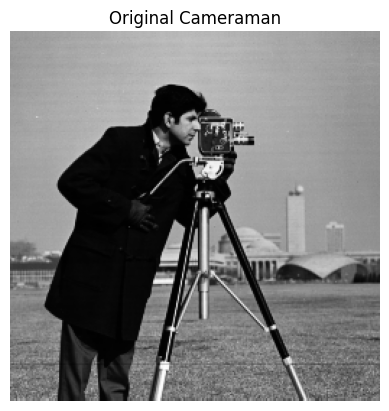

In [2]:
from skimage import io
from skimage.transform import resize

image = io.imread('cameraman.tif', as_gray=True)
image = resize(image, (256, 256))

M, N = image.shape

plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.show()

In [3]:
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

In [4]:
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape

    cy, cx = ph // 2, pw // 2

    padded[
        cy - kh//2 : cy - kh//2 + kh,
        cx - kw//2 : cx - kw//2 + kw
    ] = kernel

    return fft2(ifftshift(padded))

In [5]:
F = fft2(image)

H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

In [6]:
F_sobel_x = F * H_x
F_sobel_y = F * H_y

In [7]:
sobel_x_result = ifft2(F_sobel_x).real
sobel_y_result = ifft2(F_sobel_y).real

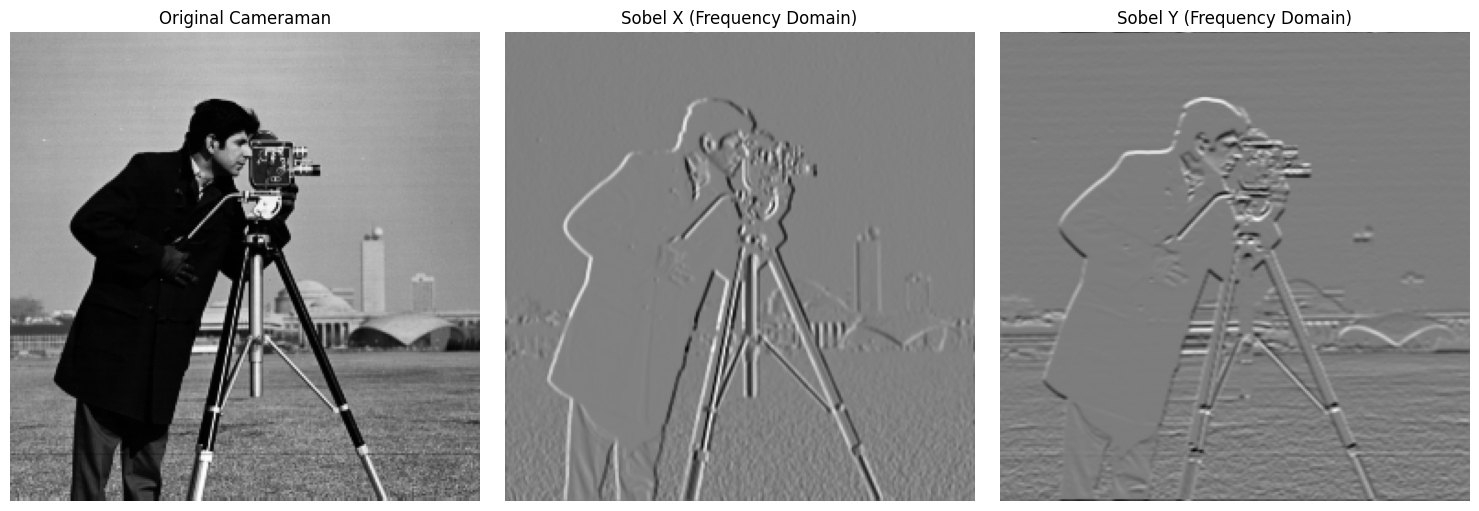

In [8]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(sobel_x_result, cmap='gray')
plt.title('Sobel X (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(sobel_y_result, cmap='gray')
plt.title('Sobel Y (Frequency Domain)')
plt.axis('off')

plt.tight_layout()
plt.show()

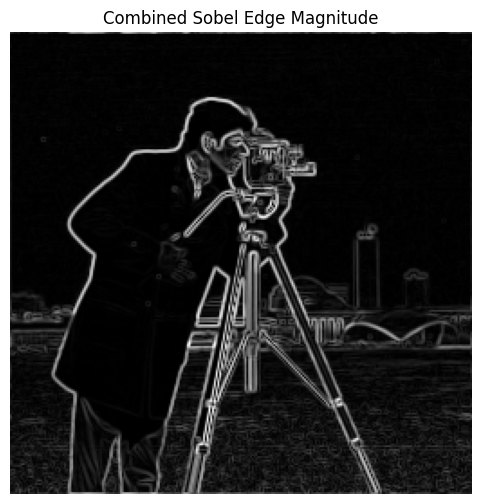

In [9]:
sobel_magnitude = np.sqrt(
    sobel_x_result**2 + sobel_y_result**2
)

plt.figure(figsize=(6, 6))
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Combined Sobel Edge Magnitude')
plt.axis('off')
plt.show()